In [1]:
pip install qiskit qiskit-aer matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.4 MB/s eta 0:00:00


**Easy**

In [4]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2, 1)

# Initialize the output qubit
qc.x(1)

# Apply Hadamard gates
qc.h(0)
qc.h(1)

# Oracle for f(x) = 0 (identity operation)
# No gate is required

# Apply Hadamard to the input qubit
qc.h(0)

# Measure the input qubit
qc.measure(0, 0)

print(qc.draw())

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
print("Output:", result.get_counts())

     ┌───┐┌───┐┌─┐
q_0: ┤ H ├┤ H ├┤M├
     ├───┤├───┤└╥┘
q_1: ┤ X ├┤ H ├─╫─
     └───┘└───┘ ║ 
c: 1/═══════════╩═
                0 
Output: {'0': 1024}


**Medium**

In [5]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2, 1)

# Initialize the output qubit
qc.x(1)

# Apply Hadamard gates
qc.h(0)
qc.h(1)

# Oracle for f(x) = x
qc.cx(0, 1)

# Apply Hadamard to the input qubit
qc.h(0)

# Measure the input qubit
qc.measure(0, 0)

print(qc.draw())

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
print("Output:", result.get_counts())

     ┌───┐          ┌───┐┌─┐
q_0: ┤ H ├───────■──┤ H ├┤M├
     ├───┤┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├──────╫─
     └───┘└───┘└───┘      ║ 
c: 1/═════════════════════╩═
                          0 
Output: {'1': 1024}


**Hard**

In [6]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def deutsch_algorithm(function_type):
    qc = QuantumCircuit(2, 1)

    # Prepare the output qubit
    qc.x(1)

    # Superposition
    qc.h(0)
    qc.h(1)

    # Oracle selection
    if function_type == "zero":
        pass
    elif function_type == "one":
        qc.x(1)
    elif function_type == "identity":
        qc.cx(0, 1)
    elif function_type == "not":
        qc.x(1)
        qc.cx(0, 1)
    else:
        raise ValueError("Invalid function type")

    # Final Hadamard and measurement
    qc.h(0)
    qc.measure(0, 0)

    return qc


simulator = AerSimulator()

for function in ["zero", "one", "identity", "not"]:
    qc = deutsch_algorithm(function)
    result = simulator.run(qc, shots=1024).result()
    counts = result.get_counts()

    print("\nFunction:", function)
    print("Counts:", counts)
    print(qc.draw())


Function: zero
Counts: {'0': 1024}
     ┌───┐┌───┐┌─┐
q_0: ┤ H ├┤ H ├┤M├
     ├───┤├───┤└╥┘
q_1: ┤ X ├┤ H ├─╫─
     └───┘└───┘ ║ 
c: 1/═══════════╩═
                0 

Function: one
Counts: {'0': 1024}
     ┌───┐┌───┐     ┌─┐
q_0: ┤ H ├┤ H ├─────┤M├
     ├───┤├───┤┌───┐└╥┘
q_1: ┤ X ├┤ H ├┤ X ├─╫─
     └───┘└───┘└───┘ ║ 
c: 1/════════════════╩═
                     0 

Function: identity
Counts: {'1': 1024}
     ┌───┐          ┌───┐┌─┐
q_0: ┤ H ├───────■──┤ H ├┤M├
     ├───┤┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├──────╫─
     └───┘└───┘└───┘      ║ 
c: 1/═════════════════════╩═
                          0 

Function: not
Counts: {'1': 1024}
     ┌───┐               ┌───┐┌─┐
q_0: ┤ H ├────────────■──┤ H ├┤M├
     ├───┤┌───┐┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├┤ X ├──────╫─
     └───┘└───┘└───┘└───┘      ║ 
c: 1/══════════════════════════╩═
                               0 


**Real-world exercise**

In [7]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2, 1)

# Prepare quantum states
qc.x(1)
qc.h(0)
qc.h(1)

# Classification oracle
qc.cx(0, 1)

# Phase kickback occurs through the oracle
qc.h(0)

# Measure the decision qubit
qc.measure(0, 0)

print(qc.draw(output="text"))

     ┌───┐          ┌───┐┌─┐
q_0: ┤ H ├───────■──┤ H ├┤M├
     ├───┤┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├──────╫─
     └───┘└───┘└───┘      ║ 
c: 1/═════════════════════╩═
                          0 


**Challenge**

Error = 0.00, Reliability = 100.00%
Error = 0.02, Reliability = 100.00%
Error = 0.05, Reliability = 99.61%
Error = 0.10, Reliability = 98.88%
Error = 0.20, Reliability = 94.48%
Error = 0.30, Reliability = 89.01%


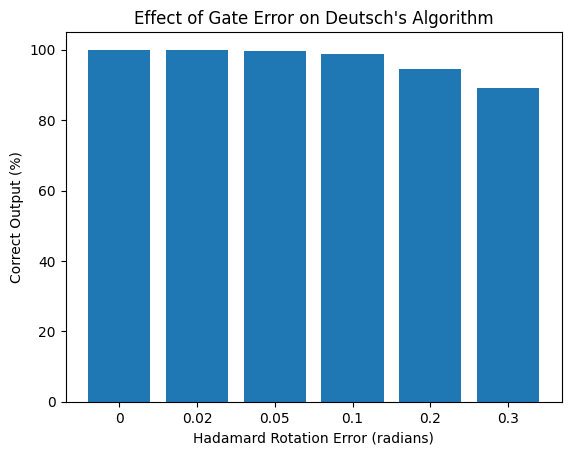

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

def imperfect_h(qc, qubit, error):
    # H = RY(pi/2) Z, up to global phase
    qc.z(qubit)
    qc.ry(np.pi / 2 + error, qubit)


def run_experiment(error):
    qc = QuantumCircuit(2, 1)

    # Initialize the output qubit
    qc.x(1)

    # Apply imperfect Hadamard gates
    imperfect_h(qc, 0, error)
    imperfect_h(qc, 1, error)

    # Balanced oracle: f(x) = x
    qc.cx(0, 1)

    # Final imperfect Hadamard
    imperfect_h(qc, 0, error)

    qc.measure(0, 0)

    result = simulator.run(qc, shots=4096).result()
    counts = result.get_counts()

    # For a balanced function, output 1 is correct
    return counts.get("1", 0) / 4096


errors = [0, 0.02, 0.05, 0.1, 0.2, 0.3]
reliability = [run_experiment(e) * 100 for e in errors]

for e, r in zip(errors, reliability):
    print(f"Error = {e:.2f}, Reliability = {r:.2f}%")

plt.bar([str(e) for e in errors], reliability)
plt.xlabel("Hadamard Rotation Error (radians)")
plt.ylabel("Correct Output (%)")
plt.title("Effect of Gate Error on Deutsch's Algorithm")
plt.ylim(0, 105)
plt.show()